<a href="https://colab.research.google.com/github/IrmaGeo/09_generate-readme/blob/master/CS584%20HW3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS 584 hw3

Irma modzgvrishvili A20597307

**Imports**

In [12]:
import os
import tarfile
import urllib.request
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Callable, Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from imageio.v2 import imread

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

# Optional progress bar
try:
    from tqdm import tqdm
    TQDM = True
except Exception:
    TQDM = False

# Reproducibility
def set_seed(seed: int = 42) -> None:
    np.random.seed(seed)

## Data Loaders
**CMU Face Images**

In [13]:
# ---- CMU Faces (UCI #124) robust downloader ----

# Correct archive names
FACES_TAR_FULL     = "faces.tar.gz"     # scales 1,2,4
FACES_TAR_QUARTER  = "faces_4.tar.gz"   # 32x30 only

# Mirrors to try (order matters)
_MIRRORS_QUARTER = [
    "https://kdd.ics.uci.edu/databases/faces/faces_4.tar.gz",
    "https://archive.ics.uci.edu/ml/machine-learning-databases/faces/faces_4.tar.gz",
    "https://archive.ics.uci.edu/static/public/124/faces_4.tar.gz",
]
_MIRRORS_FULL = [
    "https://kdd.ics.uci.edu/databases/faces/faces.tar.gz",
    "https://archive.ics.uci.edu/ml/machine-learning-databases/faces/faces.tar.gz",
    "https://archive.ics.uci.edu/static/public/124/faces.tar.gz",
]

POSES = {"straight", "left", "right", "up"}
EXPRESSIONS = {"neutral", "happy", "sad", "angry"}
EYES = {"open", "sunglasses"}

def _urlretrieve_with_headers(url: str, dst: Path):
    opener = urllib.request.build_opener()
    opener.addheaders = [("User-Agent", "Mozilla/5.0 (compatible; HW3-Downloader)")]
    urllib.request.install_opener(opener)
    urllib.request.urlretrieve(url, dst)

def _download_from_mirrors(dst: Path, is_quarter: bool) -> None:
    mirrors = _MIRRORS_QUARTER if is_quarter else _MIRRORS_FULL
    last_err = None
    for url in mirrors:
        try:
            print(f"Downloading from {url} ...")
            _urlretrieve_with_headers(url, dst)
            print("✔ Downloaded.")
            return
        except Exception as e:
            print(f"  ↳ failed: {e}")
            last_err = e
    raise RuntimeError("Could not download CMU Faces from any mirror.") from last_err

def _guess_image_root(extract_dir: Path) -> Path:
    # 1) expected subfolders
    for name in ("faces4", "faces"):
        p = extract_dir / name
        if p.exists() and list(p.rglob("*.pgm")):
            return p
    # 2) .pgm directly or nested
    if list(extract_dir.rglob("*.pgm")):
        return extract_dir
    # 3) one-level search
    for sub in extract_dir.iterdir():
        if sub.is_dir() and list(sub.rglob("*.pgm")):
            return sub
    raise RuntimeError("Extraction completed but no .pgm files found.")

def download_and_extract_cmu_faces(data_dir: Path, quarter_scale_only: bool = True) -> Path:
    data_dir.mkdir(parents=True, exist_ok=True)
    tar_name = FACES_TAR_QUARTER if quarter_scale_only else FACES_TAR_FULL
    tar_path = data_dir / tar_name

    # already extracted?
    try:
        root_guess = _guess_image_root(data_dir)
        print(f"✔ Found existing images at {root_guess}")
        return root_guess
    except Exception:
        pass

    # download if needed
    if not tar_path.exists():
        _download_from_mirrors(tar_path, is_quarter=quarter_scale_only)

    # extract safely
    print(f"Extracting {tar_name} ...")
    with tarfile.open(tar_path, "r:gz") as tf:
        def is_within_directory(directory, target):
            abs_directory = os.path.abspath(directory)
            abs_target = os.path.abspath(target)
            prefix = os.path.commonprefix([abs_directory, abs_target])
            return prefix == abs_directory
        def safe_extract(tar, path=".", members=None, *, numeric_owner=False):
            for member in tar.getmembers():
                member_path = os.path.join(path, member.name)
                if not is_within_directory(path, member_path):
                    raise Exception("Attempted Path Traversal in Tar File")
            tar.extractall(path, members, numeric_owner=numeric_owner)
        safe_extract(tf, path=data_dir)
    print("✔ Extraction complete.")

    root = _guess_image_root(data_dir)
    print(f"✔ Using image root: {root}")
    return root

def _parse_face_filename(fname: str):
    base = os.path.basename(fname)
    if not base.endswith(".pgm"):
        return None
    name = base[:-4]
    parts = name.split("_")
    if len(parts) < 5:
        return None
    pose, expr, eyes, scale = parts[-4], parts[-3], parts[-2], parts[-1]
    subject = "_".join(parts[:-4])
    if pose not in POSES or expr not in EXPRESSIONS or eyes not in EYES:
        return None
    try:
        int(scale)
    except Exception:
        return None
    return subject, pose, expr, eyes, int(scale)

def load_cmu_faces_matrix(root: Path, use_scale: int = 4) -> Dict[str, Any]:
    files = sorted([str(p) for p in root.rglob("*.pgm") if not str(p).endswith(".bad")])

    X, eyes, pose, expr, subj_names, filelist = [], [], [], [], [], []
    pose_map = {"straight": 0, "left": 1, "right": 2, "up": 3}
    expr_order = ["angry", "happy", "neutral", "sad"]
    expr_map = {e: i for i, e in enumerate(expr_order)}

    iterator = tqdm(files, desc="Reading CMU Faces") if TQDM else files
    for f in iterator:
        parsed = _parse_face_filename(f)
        if not parsed:
            continue
        s, p, e, g, scale = parsed
        if scale != use_scale:
            continue

        img = imread(f).astype(np.float32)
        if img.max() > 0:
            img = img / 255.0
        X.append(img.flatten())
        filelist.append(f)
        subj_names.append(s)
        eyes.append(0 if g == "open" else 1)
        pose.append(pose_map[p])
        expr.append(expr_map[e])

    if not X:
        raise RuntimeError("No images loaded. Check extraction path/scale.")
    X = np.vstack(X).astype(np.float32)

    unique_subjects = sorted(set(subj_names))
    id_map = {s: i for i, s in enumerate(unique_subjects)}
    y_id = np.array([id_map[s] for s in subj_names], dtype=int)

    return {
        "X": X,
        "y_eyes": np.array(eyes, dtype=int),
        "y_pose": np.array(pose, dtype=int),
        "y_expr": np.array(expr, dtype=int),
        "y_id": y_id,
        "meta": {
            "files": filelist,
            "subject_names": unique_subjects,
            "pose_map": pose_map,
            "expr_map": expr_map,
            "eyes_map": {"open": 0, "sunglasses": 1},
            "id_map": id_map,
            "scale": use_scale
        }
    }


**Iris (tabular) + Generic CSV**

In [14]:
# ---- Iris loaders (binary + multiclass) ----
from sklearn.datasets import load_iris  # only here (single import)

def load_iris_multiclass(standardize: bool = True) -> Tuple[np.ndarray, np.ndarray, List[str], Optional[StandardScaler]]:
    ds = load_iris()
    X = ds.data.astype(float)
    y = ds.target.astype(int)
    scaler = None
    if standardize:
        scaler = StandardScaler()
        X = scaler.fit_transform(X)
    return X, y, list(ds.feature_names), scaler

def load_iris_binary(positive_class: str = "setosa", standardize: bool = True) -> Tuple[np.ndarray, np.ndarray, List[str], Optional[StandardScaler]]:
    name_to_idx = {"setosa": 0, "versicolor": 1, "virginica": 2}
    if positive_class not in name_to_idx:
        raise ValueError("positive_class must be one of: setosa, versicolor, virginica")
    pos = name_to_idx[positive_class]
    ds = load_iris()
    X = ds.data.astype(float)
    y = (ds.target == pos).astype(int)
    scaler = None
    if standardize:
        scaler = StandardScaler()
        X = scaler.fit_transform(X)
    return X, y, list(ds.feature_names), scaler

# ---- Generic tabular CSV loader ----
def load_tabular_from_csv(
    csv_path: str,
    target_col: str,
    categorical: Optional[List[str]] = None
) -> Tuple[np.ndarray, np.ndarray, List[str], StandardScaler]:
    df = pd.read_csv(csv_path)
    if target_col not in df.columns:
        raise ValueError(f"target_col '{target_col}' not in CSV.")
    y = df[target_col].values
    Xdf = df.drop(columns=[target_col]).copy()

    if categorical:
        Xdf = pd.get_dummies(Xdf, columns=categorical, drop_first=False)

    feat_names = Xdf.columns.tolist()
    X = Xdf.values.astype(np.float64)
    scaler = StandardScaler()
    Xs = scaler.fit_transform(X)
    return Xs, y.astype(int), feat_names, scaler


## Feature Utilities

In [15]:
def poly2_features(X: np.ndarray) -> np.ndarray:
    n, d = X.shape
    feats = [X, X**2]
    inters = []
    for i in range(d):
        for j in range(i+1, d):
            inters.append((X[:, i] * X[:, j])[:, None])
    if inters:
        feats.append(np.hstack(inters))
    return np.hstack(feats)

class Poly2:
    def fit(self, X: np.ndarray, y: Optional[np.ndarray] = None):
        return self
    def transform(self, X: np.ndarray) -> np.ndarray:
        return poly2_features(X)


## Evaluation Helpers

In [16]:
# ---- Metrics container ----
@dataclass
class Metrics:
    accuracy: float
    precision: float
    recall: float
    f1: float
    confusion: np.ndarray

def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, average: str = "macro") -> Metrics:
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average=average, zero_division=0)
    rec = recall_score(y_true, y_pred, average=average, zero_division=0)
    f1  = f1_score(y_true, y_pred, average=average, zero_division=0)
    return Metrics(acc, prec, rec, f1, cm)

# ---- Cross-validation (leakage-safe) ----
def cross_validate(
    model_factory: Callable[[], Any],
    X: np.ndarray,
    y: np.ndarray,
    k_folds: int = 5,
    average: str = "macro",
    transformer_factories: Optional[List[Callable[[], Any]]] = None,
    seed: int = 42
) -> Dict[str, Any]:
    skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=seed)
    accs, precs, recs, f1s = [], [], [], []
    cm_sum = None

    for tr, va in skf.split(X, y):
        Xtr, Xva = X[tr], X[va]
        ytr, yva = y[tr], y[va]

        # per-fold transforms (no leakage)
        if transformer_factories:
            for make in transformer_factories:
                tfm = make()
                Xtr = tfm.fit_transform(Xtr) if hasattr(tfm, "fit_transform") else tfm.fit(Xtr, ytr).transform(Xtr)  # type: ignore
                Xva = tfm.transform(Xva)

        model = model_factory()
        model.fit(Xtr, ytr)
        yhat = model.predict(Xva)

        m = compute_metrics(yva, yhat, average=average)
        accs.append(m.accuracy); precs.append(m.precision); recs.append(m.recall); f1s.append(m.f1)
        cm_sum = m.confusion if cm_sum is None else (cm_sum + m.confusion)

    return {
        "accuracy_mean": float(np.mean(accs)),
        "accuracy_std":  float(np.std(accs)),
        "precision_mean":float(np.mean(precs)),
        "recall_mean":   float(np.mean(recs)),
        "f1_mean":       float(np.mean(f1s)),
        "confusion_matrix_sum_over_folds": cm_sum
    }

# ---- Parameter grid sweeps ----
def sweep_params(
    param_grid: Dict[str, List[Any]],
    model_builder: Callable[[Dict[str, Any]], Any],
    X: np.ndarray,
    y: np.ndarray,
    k_folds: int = 5,
    average: str = "macro",
    transformers: Optional[List[Callable[[], Any]]] = None,
    seed: int = 42
) -> pd.DataFrame:
    keys = list(param_grid.keys())
    lists = [param_grid[k] for k in keys]
    if not keys:
        combos = [dict()]
    else:
        combos = np.array(np.meshgrid(*lists, indexing="ij")).reshape(len(keys), -1).T
        combos = [{k: v for k, v in zip(keys, row)} for row in combos]

    rows = []
    for params in combos:
        def mf(): return model_builder(params)
        res = cross_validate(mf, X, y, k_folds=k_folds, average=average, transformer_factories=transformers, seed=seed)
        rows.append({**params, **res})
    return pd.DataFrame(rows)


## Plotting Helpers

In [17]:
def plot_metric_curve(
    df: pd.DataFrame,
    x: str,
    y: str,
    title: str,
    xlabel: Optional[str] = None,
    ylabel: Optional[str] = None
) -> None:
    plt.figure()
    plt.plot(df[x], df[y], marker='o')
    plt.title(title)
    plt.xlabel(xlabel or x)
    plt.ylabel(ylabel or y)
    plt.grid(True)
    plt.show()

def plot_confusion_matrix(cm: np.ndarray, class_names: Optional[List[str]] = None, title: str = "Confusion Matrix") -> None:
    plt.figure()
    plt.imshow(cm, interpolation='nearest')
    plt.title(title)
    plt.colorbar()
    ticks = np.arange(cm.shape[0])
    if class_names:
        plt.xticks(ticks, class_names, rotation=45, ha='right')
        plt.yticks(ticks, class_names)
    else:
        plt.xticks(ticks, ticks)
        plt.yticks(ticks, ticks)
    plt.tight_layout()
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()


## 1. Logistic Regression

In [18]:
# ---- Model primitives ----
def _add_bias(X: np.ndarray) -> np.ndarray:
    return np.hstack([X, np.ones((X.shape[0], 1), dtype=X.dtype)])

def _sigmoid(z: np.ndarray) -> np.ndarray:
    z = np.clip(z, -40, 40)
    return 1.0 / (1.0 + np.exp(-z))

def _softmax(Z: np.ndarray) -> np.ndarray:
    Z = np.clip(Z, -40, 40)
    Z = Z - Z.max(axis=1, keepdims=True)
    EZ = np.exp(Z)
    return EZ / (EZ.sum(axis=1, keepdims=True) + 1e-12)

# ---- Binary LR ----
@dataclass
class LogisticRegressionBinary:
    lr: float = 1e-1
    reg_lambda: float = 1e-2
    max_iter: int = 2000
    tol: float = 1e-7
    fit_intercept: bool = True
    verbose: bool = False
    random_state: int = 42

    def _init_w(self, d: int):
        rng = np.random.default_rng(self.random_state)
        self.w_ = rng.normal(0, 0.01, size=(d + (1 if self.fit_intercept else 0),))

    def fit(self, X: np.ndarray, y: np.ndarray):
        Xb = _add_bias(X) if self.fit_intercept else X
        N, d = Xb.shape
        self._init_w(d - (1 if self.fit_intercept else 0))
        w = self.w_
        for it in range(self.max_iter):
            p = _sigmoid(Xb @ w)
            grad = (Xb.T @ (p - y)) / N
            if self.fit_intercept:
                grad[:-1] += self.reg_lambda * w[:-1]
            else:
                grad += self.reg_lambda * w
            w_new = w - self.lr * grad
            if np.linalg.norm(w_new - w) < self.tol:
                if self.verbose:
                    print(f"[BinaryLR] Converged at iter {it}")
                w = w_new
                break
            w = w_new
        self.w_ = w
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        Xb = _add_bias(X) if self.fit_intercept else X
        p1 = _sigmoid(Xb @ self.w_)
        return np.vstack([1 - p1, p1]).T

    def predict(self, X: np.ndarray) -> np.ndarray:
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

# ---- Multiclass (Softmax) LR ----
@dataclass
class LogisticRegressionSoftmax:
    lr: float = 1e-1
    reg_lambda: float = 1e-2
    max_iter: int = 2000
    tol: float = 1e-7
    fit_intercept: bool = True
    verbose: bool = False
    random_state: int = 42

    def _init_W(self, d: int, K: int):
        rng = np.random.default_rng(self.random_state)
        self.W_ = rng.normal(0, 0.01, size=(d + (1 if self.fit_intercept else 0), K))

    def fit(self, X: np.ndarray, y: np.ndarray):
        classes = np.unique(y)
        self.classes_ = classes
        K = classes.size
        Xb = _add_bias(X) if self.fit_intercept else X
        N, d = Xb.shape
        self._init_W(d - (1 if self.fit_intercept else 0), K)

        Y = np.zeros((N, K), dtype=X.dtype)
        Y[np.arange(N), y] = 1.0
        W = self.W_
        for it in range(self.max_iter):
            P = _softmax(Xb @ W)
            grad = (Xb.T @ (P - Y)) / N
            if self.fit_intercept:
                grad[:-1, :] += self.reg_lambda * W[:-1, :]
            else:
                grad += self.reg_lambda * W
            W_new = W - self.lr * grad
            if np.linalg.norm(W_new - W) < self.tol:
                if self.verbose:
                    print(f"[SoftmaxLR] Converged at iter {it}")
                W = W_new
                break
            W = W_new
        self.W_ = W
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        Xb = _add_bias(X) if self.fit_intercept else X
        return _softmax(Xb @ self.W_)

    def predict(self, X: np.ndarray) -> np.ndarray:
        P = self.predict_proba(X)
        idx = np.argmax(P, axis=1)
        return self.classes_[idx]


**Load Datasets**

In [19]:
set_seed(42)

# Image dataset: CMU Faces (quarter scale 32x30)
root = download_and_extract_cmu_faces(Path("cmu_faces_data"), quarter_scale_only=True)
faces = load_cmu_faces_matrix(root, use_scale=4)
X_img  = faces["X"]
y_eyes = faces["y_eyes"]      # binary (open vs sunglasses)
y_pose = faces["y_pose"]      # 4-class
y_expr = faces["y_expr"]      # 4-class
y_id   = faces["y_id"]        # 20-class

# Tabular dataset: Iris (binary + multiclass)
X_iris_bin, y_iris_bin, _, _ = load_iris_binary("setosa", standardize=True)
X_iris_mc,  y_iris_mc,  _, _ = load_iris_multiclass(standardize=True)


✔ Found existing images at cmu_faces_data


Reading CMU Faces: 100%|██████████| 624/624 [00:00<00:00, 649.19it/s]


### 1.1 Subtask 1 — Binary LR


=== Subtask 1: Binary LR — CMU Faces (Eyes: open vs sunglasses) ===
{'accuracy_mean': 0.929483870967742, 'accuracy_std': 0.02790457949354832, 'precision_mean': 0.9352621859602295, 'recall_mean': 0.9227854582693293, 'f1_mean': 0.9288730133752952}


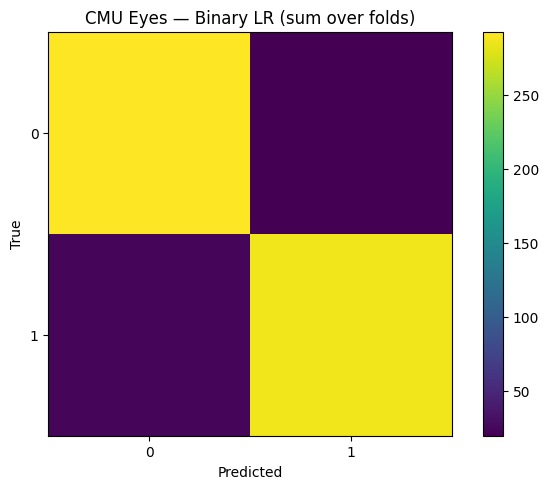


=== Subtask 1: Binary LR — Iris (setosa vs rest) ===
{'accuracy_mean': 1.0, 'accuracy_std': 0.0, 'precision_mean': 1.0, 'recall_mean': 1.0, 'f1_mean': 1.0}


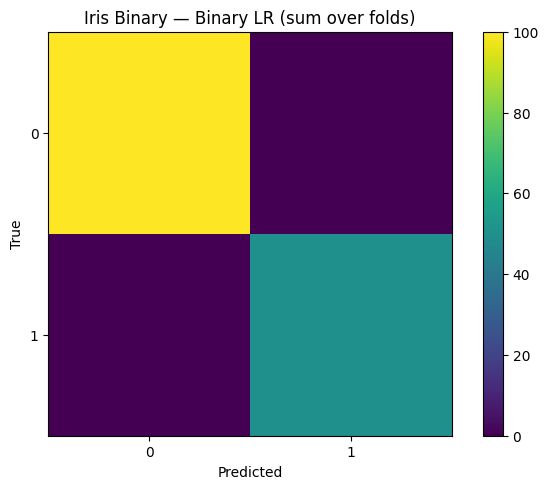

In [20]:
print("\n=== Subtask 1: Binary LR — CMU Faces (Eyes: open vs sunglasses) ===")
res_bin_img = cross_validate(
    model_factory=lambda: LogisticRegressionBinary(lr=0.1, reg_lambda=1e-2, max_iter=2000),
    X=X_img, y=y_eyes,
    k_folds=5, average="binary",
    transformer_factories=[lambda: StandardScaler()],
    seed=42
)
print({k: v for k, v in res_bin_img.items() if k != "confusion_matrix_sum_over_folds"})
plot_confusion_matrix(res_bin_img["confusion_matrix_sum_over_folds"], title="CMU Eyes — Binary LR (sum over folds)")

print("\n=== Subtask 1: Binary LR — Iris (setosa vs rest) ===")
res_bin_tab = cross_validate(
    model_factory=lambda: LogisticRegressionBinary(lr=0.1, reg_lambda=1e-2, max_iter=2000),
    X=X_iris_bin, y=y_iris_bin,
    k_folds=5, average="binary",
    transformer_factories=None,  # already standardized in loader
    seed=42
)
print({k: v for k, v in res_bin_tab.items() if k != "confusion_matrix_sum_over_folds"})
plot_confusion_matrix(res_bin_tab["confusion_matrix_sum_over_folds"], title="Iris Binary — Binary LR (sum over folds)")


### 1.2 Subtask 2 — Non-linear feature extensions


=== Subtask 2A: PCA sweep — Binary LR on CMU Eyes ===
   pca_dims  accuracy_mean  precision_mean  recall_mean   f1_mean
0        50       0.806013        0.815137     0.794009  0.803178
1       100       0.911845        0.917600     0.906605  0.911284
2       200       0.915045        0.926027     0.903482  0.914074


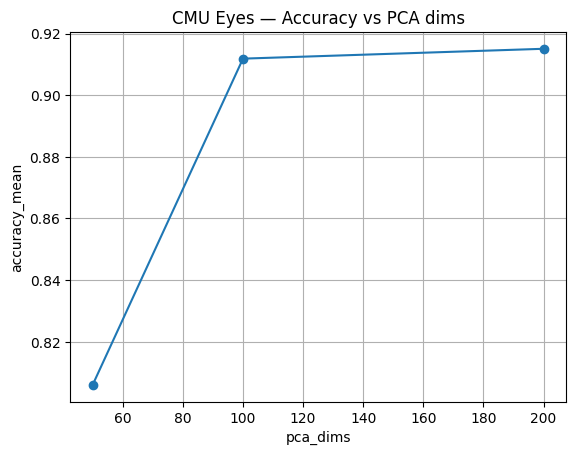


=== Subtask 2B: Poly2 features — Binary LR on Iris Binary ===
     lr  reg_lambda  accuracy_mean  precision_mean  recall_mean  f1_mean
0  0.05       0.010            1.0             1.0          1.0      1.0
1  0.05       0.001            1.0             1.0          1.0      1.0
2  0.10       0.010            1.0             1.0          1.0      1.0
3  0.10       0.001            1.0             1.0          1.0      1.0


In [21]:
# 2A) PCA sweeps for CMU Eyes
print("\n=== Subtask 2A: PCA sweep — Binary LR on CMU Eyes ===")
rows = []
for k in [50, 100, 200]:
    df_k = sweep_params(
        param_grid={"lr": [0.1], "reg_lambda": [1e-2]},
        model_builder=lambda p: LogisticRegressionBinary(lr=p["lr"], reg_lambda=p["reg_lambda"], max_iter=2000),
        X=X_img, y=y_eyes,
        k_folds=5, average="binary",
        transformers=[lambda: StandardScaler(), lambda: PCA(n_components=k, random_state=42)],
        seed=42
    )
    df_k.insert(0, "pca_dims", k)
    rows.append(df_k)
pca_results = pd.concat(rows, ignore_index=True)
print(pca_results[["pca_dims", "accuracy_mean", "precision_mean", "recall_mean", "f1_mean"]])
plot_metric_curve(
    pca_results.groupby("pca_dims", as_index=False)["accuracy_mean"].mean(),
    x="pca_dims", y="accuracy_mean", title="CMU Eyes — Accuracy vs PCA dims"
)

# 2B) Poly2 on Iris Binary
print("\n=== Subtask 2B: Poly2 features — Binary LR on Iris Binary ===")
poly2_df = sweep_params(
    param_grid={"lr": [0.05, 0.1], "reg_lambda": [1e-2, 1e-3]},
    model_builder=lambda p: LogisticRegressionBinary(lr=p["lr"], reg_lambda=p["reg_lambda"], max_iter=2000),
    X=X_iris_bin, y=y_iris_bin,
    k_folds=5, average="binary",
    transformers=[lambda: Poly2(), lambda: StandardScaler()],
    seed=42
)
print(poly2_df[["lr", "reg_lambda", "accuracy_mean", "precision_mean", "recall_mean", "f1_mean"]])


### 1.3 Subtask 3 — K-class (Softmax) LR


=== Subtask 3: Softmax LR + PCA — CMU Pose (4-way) ===
   pca_dims  accuracy_mean  precision_mean  recall_mean   f1_mean
0        50       0.932697        0.934380     0.932611  0.932590
1       100       0.943923        0.947175     0.943952  0.944157
2       200       0.948735        0.952252     0.948740  0.949072

=== Subtask 3: Softmax LR + PCA — CMU Expression (4-way) ===
   pca_dims  accuracy_mean  precision_mean  recall_mean   f1_mean
0        50       0.219535        0.198877     0.219153  0.173182
1       100       0.197110        0.181885     0.197480  0.174997
2       200       0.211535        0.204886     0.211038  0.203689

=== Subtask 3: Softmax LR + PCA — CMU Identity (20-way) ===
   pca_dims  accuracy_mean  precision_mean  recall_mean   f1_mean
0        50         0.9952        0.995714     0.995476  0.995245
1       100         0.9968        0.997143     0.997143  0.996923
2       200         0.9968        0.997143     0.997143  0.996923

=== Subtask 3: Softmax LR — 

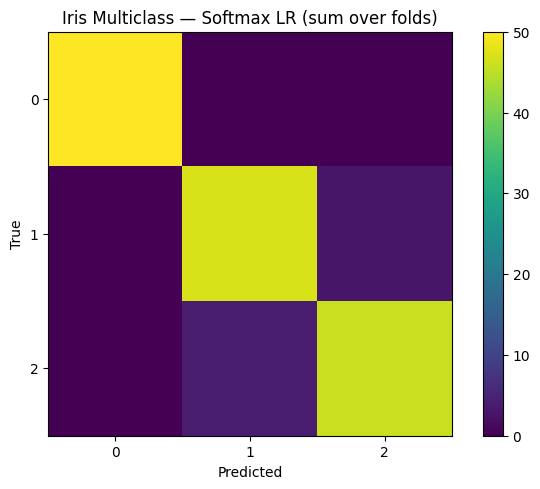

In [22]:
def run_softmax_with_pca(label: str, X: np.ndarray, y: np.ndarray, ks=[50, 100, 200]) -> pd.DataFrame:
    print(f"\n=== Subtask 3: Softmax LR + PCA — {label} ===")
    rows = []
    for k in ks:
        df_k = sweep_params(
            param_grid={"lr": [0.1], "reg_lambda": [1e-2]},
            model_builder=lambda p: LogisticRegressionSoftmax(lr=p["lr"], reg_lambda=p["reg_lambda"], max_iter=2000),
            X=X, y=y,
            k_folds=5, average="macro",
            transformers=[lambda: StandardScaler(), lambda: PCA(n_components=k, random_state=42)],
            seed=42
        )
        df_k.insert(0, "pca_dims", k)
        rows.append(df_k)
    out = pd.concat(rows, ignore_index=True)
    print(out[["pca_dims","accuracy_mean","precision_mean","recall_mean","f1_mean"]])
    return out

pose_df = run_softmax_with_pca("CMU Pose (4-way)", X_img, y_pose)
expr_df = run_softmax_with_pca("CMU Expression (4-way)", X_img, y_expr)
id_df   = run_softmax_with_pca("CMU Identity (20-way)", X_img, y_id)

print("\n=== Subtask 3: Softmax LR — Iris Multiclass (3-way) ===")
res_iris_mc = cross_validate(
    model_factory=lambda: LogisticRegressionSoftmax(lr=0.1, reg_lambda=1e-2, max_iter=2000),
    X=X_iris_mc, y=y_iris_mc,
    k_folds=5, average="macro",
    transformer_factories=None,
    seed=42
)
print({k: v for k, v in res_iris_mc.items() if k != "confusion_matrix_sum_over_folds"})
plot_confusion_matrix(res_iris_mc["confusion_matrix_sum_over_folds"], title="Iris Multiclass — Softmax LR (sum over folds)")


### 1.4 Subtask 4 — Cross-dataset evaluation (summary)

In [23]:
def best_row_by(df: pd.DataFrame, key: str = "accuracy_mean") -> pd.Series:
    return df.loc[df[key].idxmax()]

summary = {
    "Best PCA for Eyes": best_row_by(pca_results).to_dict(),
    "Best Poly2 for Iris Binary": best_row_by(poly2_df).to_dict()
}
print("\n=== Quick best-setting summary ===")
for name, row in summary.items():
    print(f"{name}: {row}")


=== Quick best-setting summary ===
Best PCA for Eyes: {'pca_dims': 200, 'lr': 0.1, 'reg_lambda': 0.01, 'accuracy_mean': 0.9150451612903225, 'accuracy_std': 0.03149165424681325, 'precision_mean': 0.9260270950684955, 'recall_mean': 0.9034818228366615, 'f1_mean': 0.9140742256816281, 'confusion_matrix_sum_over_folds': array([[290,  23],
       [ 30, 281]])}
Best Poly2 for Iris Binary: {'lr': 0.05, 'reg_lambda': 0.01, 'accuracy_mean': 1.0, 'accuracy_std': 0.0, 'precision_mean': 1.0, 'recall_mean': 1.0, 'f1_mean': 1.0, 'confusion_matrix_sum_over_folds': array([[100,   0],
       [  0,  50]])}


## 2. Multilayer Perceptron (MLP)
**2.1 Theory**

**2.2 Implementation:**

In [24]:
# ========= 8.2.1 — Two-layer MLP (sigmoid hidden, softmax output) =========
# Uses your existing helpers: cross_validate, sweep_params, StandardScaler, PCA, etc.

from dataclasses import dataclass

@dataclass
class MLP2Layer:
    # architecture
    input_dim: int
    hidden_dim: int = 64
    output_dim: int = 3
    # optimization
    lr: float = 0.1
    momentum: float = 0.0
    l2: float = 1e-4
    max_epochs: int = 200
    batch_size: int = 64
    # misc
    random_state: int = 42
    verbose: bool = False

    # ---- safety casts (handle np scalar types from sweeps) ----
    def __post_init__(self):
        self.input_dim   = int(self.input_dim)
        self.hidden_dim  = int(self.hidden_dim)
        self.output_dim  = int(self.output_dim)
        self.max_epochs  = int(self.max_epochs)
        self.batch_size  = int(self.batch_size)
        self.lr          = float(self.lr)
        self.momentum    = float(self.momentum)
        self.l2          = float(self.l2)

    # ---- parameter init ----
    def _init_params(self):
        in_dim  = int(self.input_dim)
        hid_dim = int(self.hidden_dim)
        out_dim = int(self.output_dim)

        rng = np.random.default_rng(self.random_state)
        # Xavier-like init for sigmoid layers
        self.W1 = rng.normal(0, np.sqrt(1.0/in_dim),  size=(in_dim,  hid_dim)).astype(np.float32)
        self.b1 = np.zeros((hid_dim,), dtype=np.float32)
        self.W2 = rng.normal(0, np.sqrt(1.0/hid_dim), size=(hid_dim, out_dim)).astype(np.float32)
        self.b2 = np.zeros((out_dim,), dtype=np.float32)

        # momentum buffers
        self.vW1 = np.zeros_like(self.W1); self.vb1 = np.zeros_like(self.b1)
        self.vW2 = np.zeros_like(self.W2); self.vb2 = np.zeros_like(self.b2)

    # ---- activations ----
    @staticmethod
    def _sigmoid(u):
        u = np.clip(u, -40, 40)
        return 1.0/(1.0+np.exp(-u))

    @staticmethod
    def _softmax(U):
        U = U - U.max(axis=1, keepdims=True)
        E = np.exp(U)
        return E / (E.sum(axis=1, keepdims=True) + 1e-12)

    @staticmethod
    def _one_hot(y, K):
        Y = np.zeros((y.shape[0], K), dtype=np.float32)
        Y[np.arange(y.shape[0]), y] = 1.0
        return Y

    # ---- forward pass ----
    def _forward(self, X):
        Z1 = X @ self.W1 + self.b1           # (N,H)
        H  = self._sigmoid(Z1)               # (N,H)
        Z2 = H @ self.W2 + self.b2           # (N,K)
        P  = self._softmax(Z2)               # (N,K)
        return Z1, H, Z2, P

    # ---- loss + gradients (softmax CE + L2 on weights) ----
    def _loss_and_grads(self, X, y):
        N = X.shape[0]
        Y = self._one_hot(y, self.output_dim)
        Z1, H, Z2, P = self._forward(X)

        ce = -np.sum(Y * np.log(P + 1e-12)) / N
        l2_term = 0.5*self.l2*(np.sum(self.W1**2) + np.sum(self.W2**2))
        loss = ce + l2_term

        dZ2 = (P - Y) / N               # (N,K)
        gW2 = H.T @ dZ2 + self.l2*self.W2
        gb2 = dZ2.sum(axis=0)

        dH  = dZ2 @ self.W2.T           # (N,H)
        dZ1 = dH * H*(1.0 - H)          # (N,H)
        gW1 = X.T @ dZ1 + self.l2*self.W1
        gb1 = dZ1.sum(axis=0)

        return loss, (gW1, gb1, gW2, gb2)

    # ---- training (mini-batch SGD with momentum) ----
    def fit(self, X: np.ndarray, y: np.ndarray):
        # re-cast in case a builder overwrote with np scalars
        self.input_dim  = int(getattr(self, "input_dim", X.shape[1]))
        self.hidden_dim = int(self.hidden_dim)
        self.output_dim = int(self.output_dim)

        if not hasattr(self, "W1"):
            self._init_params()

        N = X.shape[0]
        idx = np.arange(N)

        for epoch in range(self.max_epochs):
            np.random.shuffle(idx)
            total_loss = 0.0

            for start in range(0, N, self.batch_size):
                batch = idx[start:start+self.batch_size]
                Xb, yb = X[batch], y[batch]

                loss, (gW1, gb1, gW2, gb2) = self._loss_and_grads(Xb, yb)
                total_loss += loss * Xb.shape[0]

                # momentum SGD update
                self.vW1 = self.momentum*self.vW1 - self.lr*gW1
                self.vb1 = self.momentum*self.vb1 - self.lr*gb1
                self.vW2 = self.momentum*self.vW2 - self.lr*gW2
                self.vb2 = self.momentum*self.vb2 - self.lr*gb2

                self.W1 += self.vW1; self.b1 += self.vb1
                self.W2 += self.vW2; self.b2 += self.vb2

            if self.verbose and (epoch % 10 == 0 or epoch == self.max_epochs-1):
                print(f"[MLP] epoch {epoch:4d}  loss={total_loss/N:.4f}")

        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        _, _, _, P = self._forward(X)
        return P

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.argmax(self.predict_proba(X), axis=1)


In [25]:
# ========= 8.2.2 — From-scratch MLP experiments + sklearn baselines =========

# ----- Iris multiclass (3-way) sweep: hidden units, lr, momentum -----
print("\n=== MLP (from scratch) — Iris Multiclass (3-way) ===")

def build_mlp_iris(params):
    return MLP2Layer(
        input_dim=int(X_iris_mc.shape[1]),
        hidden_dim=int(params["hidden"]),
        output_dim=int(len(np.unique(y_iris_mc))),
        lr=float(params["lr"]),
        momentum=float(params["momentum"]),
        l2=float(params["l2"]),
        max_epochs=int(params["epochs"]),
        batch_size=int(params["bs"]),
        random_state=42,
        verbose=False
    )

mlp_grid_iris = {
    "hidden":   [16, 32, 64],
    "lr":       [0.05, 0.1],
    "momentum": [0.0, 0.9],
    "l2":       [1e-4],
    "epochs":   [150],
    "bs":       [32],
}

mlp_iris_df = sweep_params(
    param_grid=mlp_grid_iris,
    model_builder=build_mlp_iris,
    X=X_iris_mc, y=y_iris_mc,
    k_folds=5, average="macro",
    transformers=None,  # Iris already standardized in your loader
    seed=42
)
print(mlp_iris_df[["hidden","lr","momentum","epochs","accuracy_mean","f1_mean"]].sort_values("accuracy_mean", ascending=False).head(10))


# ----- CMU Pose (4-way) with StandardScaler+PCA per fold -----
print("\n=== MLP (from scratch) — CMU Pose (4-way) with PCA ===")

def make_pose_factory(params):
    # input features after PCA have dimension = params["pca"]
    def factory():
        return MLP2Layer(
            input_dim=int(params["pca"]),
            hidden_dim=int(params["hidden"]),
            output_dim=int(len(np.unique(y_pose))),
            lr=float(params["lr"]),
            momentum=float(params["momentum"]),
            l2=float(params["l2"]),
            max_epochs=int(params["epochs"]),
            batch_size=int(params["bs"]),
            random_state=42,
            verbose=False
        )
    return factory

mlp_grid_pose = {
    "pca":      [50, 100, 200],
    "hidden":   [64, 128],
    "lr":       [0.05, 0.1],
    "momentum": [0.0, 0.9],
    "l2":       [1e-4],
    "epochs":   [200],
    "bs":       [64],
}

pose_rows = []
for pca_dim in mlp_grid_pose["pca"]:
    transformers = [lambda: StandardScaler(), lambda: PCA(n_components=int(pca_dim), random_state=42)]

    # expand the rest of grid
    _keys  = ["hidden","lr","momentum","l2","epochs","bs"]
    _lists = [mlp_grid_pose[k] for k in _keys]
    combos = np.array(np.meshgrid(*_lists, indexing="ij")).reshape(len(_keys), -1).T
    combos = [{k: v for k, v in zip(_keys, row)} for row in combos]

    for params in combos:
        params_all = {**params, "pca": int(pca_dim)}
        res = cross_validate(
            model_factory=make_pose_factory(params_all),
            X=X_img, y=y_pose,
            k_folds=5, average="macro",
            transformer_factories=transformers,
            seed=42
        )
        pose_rows.append({**params_all, **res})

mlp_pose_df = pd.DataFrame(pose_rows)
print(
    mlp_pose_df[["pca","hidden","lr","momentum","epochs","accuracy_mean","f1_mean"]]
    .sort_values("accuracy_mean", ascending=False)
    .head(10)
)

# (Optional) Best-setting helpers for your write-up
def best_row_by(df: pd.DataFrame, key="accuracy_mean"):
    return df.loc[df[key].idxmax()] if len(df) else None

print("\nBest Iris MLP settings:", best_row_by(mlp_iris_df).to_dict())
print("Best Pose  MLP settings:", best_row_by(mlp_pose_df).to_dict())



=== MLP (from scratch) — Iris Multiclass (3-way) ===
    hidden    lr  momentum  epochs  accuracy_mean   f1_mean
1     16.0  0.05       0.9   150.0       0.966667  0.966617
3     16.0  0.10       0.9   150.0       0.966667  0.966617
7     32.0  0.10       0.9   150.0       0.960000  0.959900
5     32.0  0.05       0.9   150.0       0.960000  0.959933
11    64.0  0.10       0.9   150.0       0.960000  0.959900
9     64.0  0.05       0.9   150.0       0.960000  0.959900
10    64.0  0.10       0.0   150.0       0.953333  0.953216
2     16.0  0.10       0.0   150.0       0.953333  0.953115
6     32.0  0.10       0.0   150.0       0.953333  0.953216
8     64.0  0.05       0.0   150.0       0.946667  0.946330

=== MLP (from scratch) — CMU Pose (4-way) with PCA ===
    pca  hidden    lr  momentum  epochs  accuracy_mean   f1_mean
7    50   128.0  0.10       0.9   200.0       0.966348  0.966103
5    50   128.0  0.05       0.9   200.0       0.964748  0.964516
23  200   128.0  0.10       0.9   2


=== sklearn MLPClassifier — Iris Multiclass (3-way) ===


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


{'accuracy_mean': 0.9733333333333333, 'accuracy_std': 0.038873012632301994, 'precision_mean': 0.9744107744107744, 'recall_mean': 0.9733333333333333, 'f1_mean': 0.9732664995822891}


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


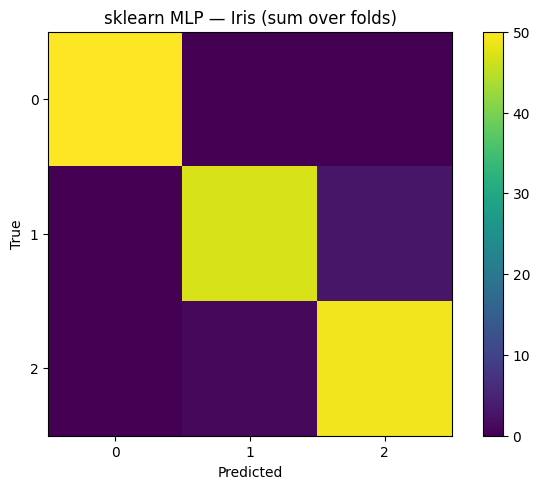


=== sklearn MLPClassifier — CMU Pose (4-way) with PCA ===
{'accuracy_mean': 0.9583483870967742, 'accuracy_std': 0.009276836089162212, 'precision_mean': 0.9603027046567665, 'recall_mean': 0.958366935483871, 'f1_mean': 0.9583137814740337}


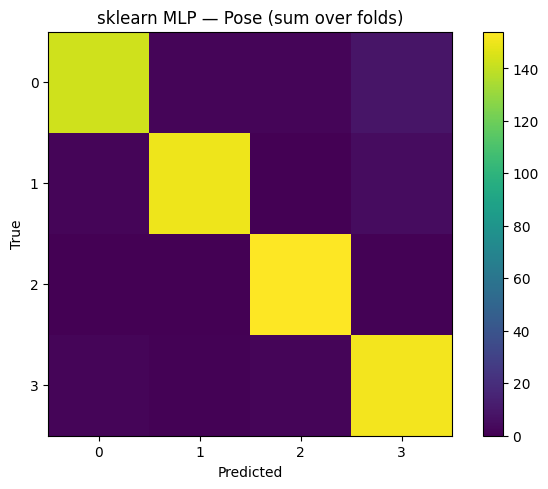

In [26]:
# ----- sklearn MLP baselines (logistic hidden to match our sigmoid) -----
from sklearn.neural_network import MLPClassifier

print("\n=== sklearn MLPClassifier — Iris Multiclass (3-way) ===")
def sk_mlp_iris_factory(hidden=64, lr=0.1, momentum=0.9, epochs=200, bs=32):
    return MLPClassifier(
        hidden_layer_sizes=(int(hidden),),
        activation="logistic",        # sigmoid hidden
        solver="sgd",
        learning_rate_init=float(lr),
        momentum=float(momentum),
        max_iter=int(epochs),
        batch_size=int(bs),
        alpha=1e-4,                   # L2
        n_iter_no_change=50,
        random_state=42
    )

res_sklearn_iris = cross_validate(
    model_factory=lambda: sk_mlp_iris_factory(hidden=64, lr=0.1, momentum=0.9, epochs=200, bs=32),
    X=X_iris_mc, y=y_iris_mc,
    k_folds=5, average="macro",
    transformer_factories=None,
    seed=42
)
print({k: v for k, v in res_sklearn_iris.items() if k != "confusion_matrix_sum_over_folds"})
plot_confusion_matrix(res_sklearn_iris["confusion_matrix_sum_over_folds"], title="sklearn MLP — Iris (sum over folds)")

print("\n=== sklearn MLPClassifier — CMU Pose (4-way) with PCA ===")
def sk_mlp_pose_factory(hidden=128, lr=0.1, momentum=0.9, epochs=200, bs=64):
    return MLPClassifier(
        hidden_layer_sizes=(int(hidden),),
        activation="logistic",
        solver="sgd",
        learning_rate_init=float(lr),
        momentum=float(momentum),
        max_iter=int(epochs),
        batch_size=int(bs),
        alpha=1e-4,
        n_iter_no_change=50,
        random_state=42
    )

res_sklearn_pose = cross_validate(
    model_factory=lambda: sk_mlp_pose_factory(hidden=128, lr=0.1, momentum=0.9, epochs=200, bs=64),
    X=X_img, y=y_pose,
    k_folds=5, average="macro",
    transformer_factories=[lambda: StandardScaler(), lambda: PCA(n_components=100, random_state=42)],
    seed=42
)
print({k: v for k, v in res_sklearn_pose.items() if k != "confusion_matrix_sum_over_folds"})
plot_confusion_matrix(res_sklearn_pose["confusion_matrix_sum_over_folds"], title="sklearn MLP — Pose (sum over folds)")


**2.3 Baseline comparison tables & quick bar plots**

,dataset,model,accuracy_mean,f1_mean,notes
0,Iris (3-class),From-scratch MLP,0.966667,0.966617,"{'hidden': 16.0, 'lr': 0.05, 'momentum': 0.9, ..."
1,Iris (3-class),sklearn MLPClassifier,0.973333,0.973266,"activation=logistic, solver=sgd, alpha=1e-4"
2,"CMU Pose (4-class, PCA)",From-scratch MLP,0.966348,0.966103,"{'hidden': 128.0, 'lr': 0.1, 'momentum': 0.9, ..."
3,"CMU Pose (4-class, PCA)",sklearn MLPClassifier,0.958348,0.958314,"activation=logistic, solver=sgd, alpha=1e-4"


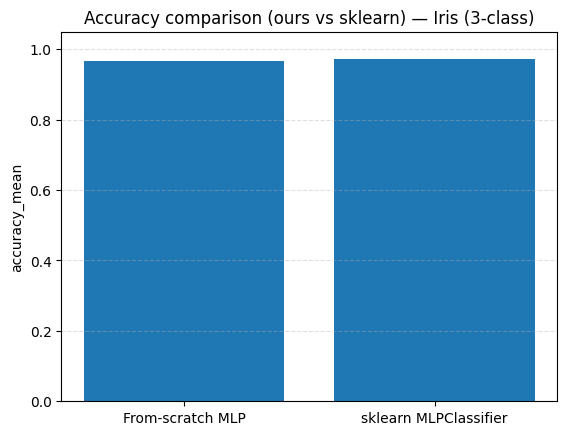

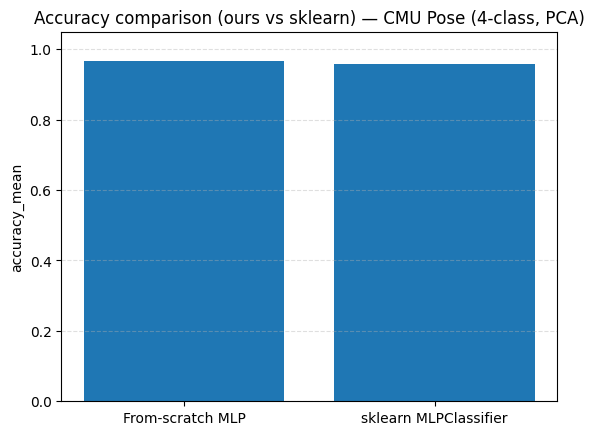

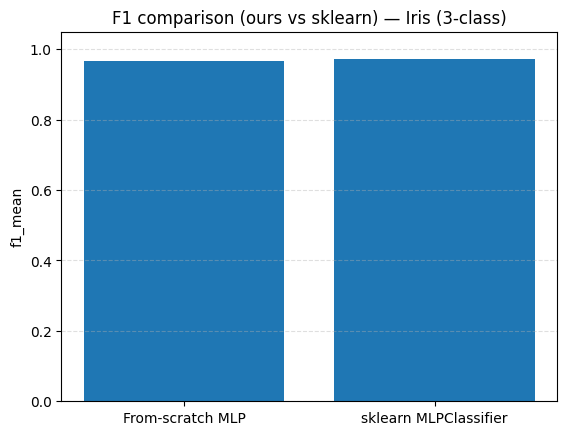

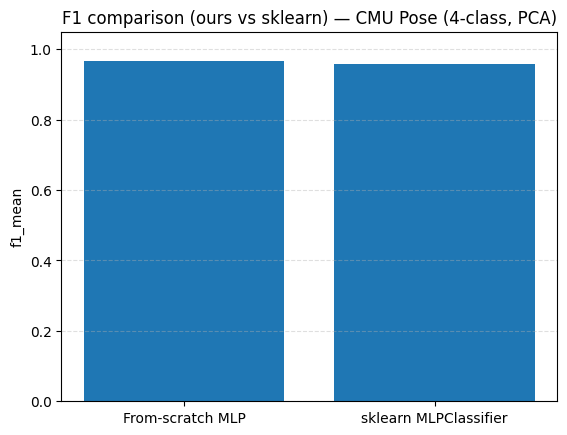

In [27]:
# ========= 8.2.3 — Baseline comparison tables & quick bar plots =========

def _best_row_by(df: pd.DataFrame, key="accuracy_mean"):
    return df.loc[df[key].idxmax()] if (df is not None and len(df)) else None

def summarize_comparison(dataset_label: str,
                         ours_df: pd.DataFrame,
                         sklearn_metrics: Dict[str, Any]) -> pd.DataFrame:
    """
    Picks the best row from our sweep (by accuracy_mean) and compares to sklearn metrics dict.
    Returns a tidy one-row-per-model DataFrame.
    """
    best = _best_row_by(ours_df, "accuracy_mean")
    rows = []
    if best is not None:
        rows.append({
            "dataset": dataset_label,
            "model": "From-scratch MLP",
            "accuracy_mean": float(best["accuracy_mean"]),
            "precision_mean": float(best["precision_mean"]),
            "recall_mean": float(best["recall_mean"]),
            "f1_mean": float(best["f1_mean"]),
            # include key hypers that defined the best setting
            "notes": {k: best[k] for k in best.index if k in ("hidden","lr","momentum","l2","epochs","bs","pca")}
        })
    if sklearn_metrics is not None:
        rows.append({
            "dataset": dataset_label,
            "model": "sklearn MLPClassifier",
            "accuracy_mean": float(sklearn_metrics["accuracy_mean"]),
            "precision_mean": float(sklearn_metrics["precision_mean"]),
            "recall_mean": float(sklearn_metrics["recall_mean"]),
            "f1_mean": float(sklearn_metrics["f1_mean"]),
            "notes": "activation=logistic, solver=sgd, alpha=1e-4"
        })
    return pd.DataFrame(rows)

# Build comparisons (assumes you already computed: mlp_iris_df, res_sklearn_iris, mlp_pose_df, res_sklearn_pose)
cmp_iris = summarize_comparison("Iris (3-class)", mlp_iris_df, res_sklearn_iris)
cmp_pose = summarize_comparison("CMU Pose (4-class, PCA)", mlp_pose_df, res_sklearn_pose)

comparison_df = pd.concat([cmp_iris, cmp_pose], ignore_index=True)
display(comparison_df[["dataset","model","accuracy_mean","f1_mean","notes"]])

# --- Quick bars for Accuracy and F1 per dataset ---
def plot_bar_compare(df: pd.DataFrame, metric: str, title: str):
    ds_list = df["dataset"].unique()
    for ds in ds_list:
        sub = df[df["dataset"] == ds]
        plt.figure()
        plt.bar(sub["model"], sub[metric])
        plt.title(f"{title} — {ds}")
        plt.ylabel(metric)
        plt.ylim(0.0, 1.05)
        plt.grid(True, axis="y", linestyle="--", alpha=0.4)
        plt.show()

plot_bar_compare(comparison_df, "accuracy_mean", "Accuracy comparison (ours vs sklearn)")
plot_bar_compare(comparison_df, "f1_mean",       "F1 comparison (ours vs sklearn)")


**2.4 Parameter studies & confusion matrices at best settings**

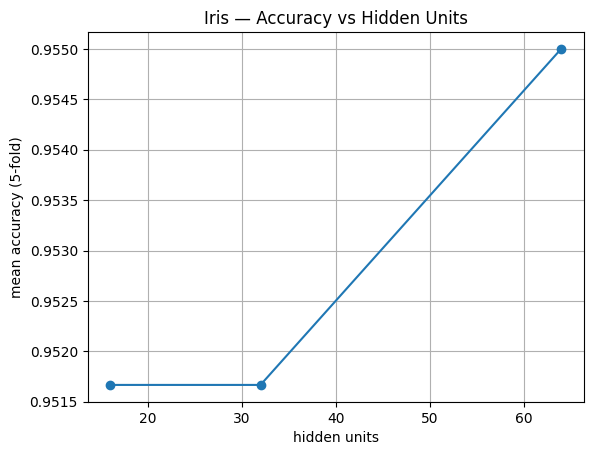

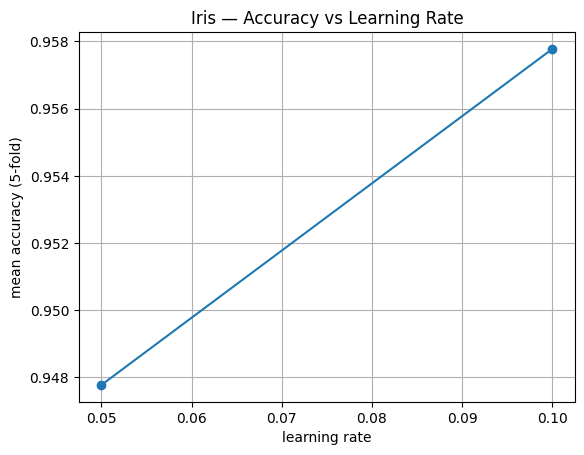

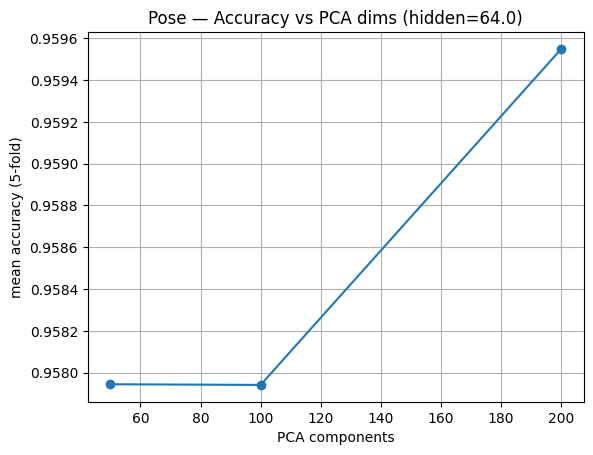

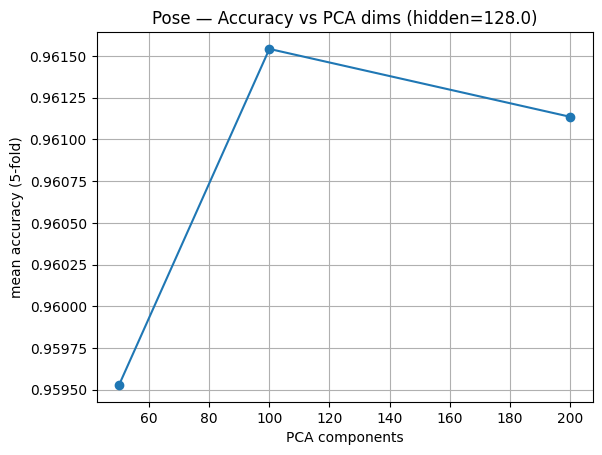

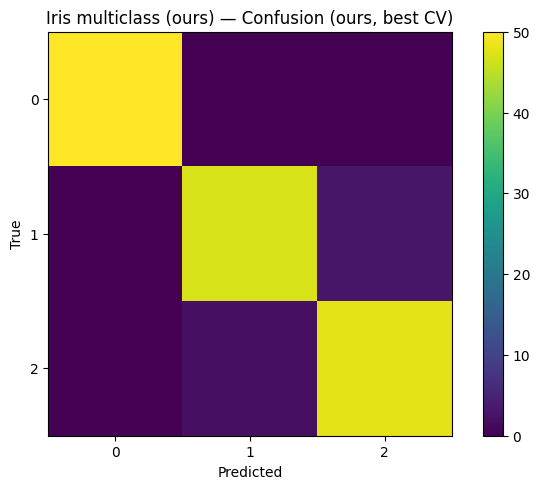

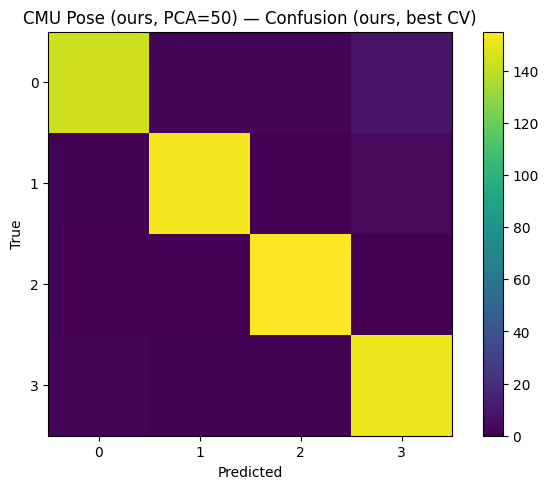

In [28]:
# ========= 8.2.4 — Parameter studies & confusion matrices at best settings =========

# ---- A) Iris: accuracy vs hidden units and vs learning rate (averaged over momentum) ----
if "mlp_iris_df" in globals() and len(mlp_iris_df):
    # accuracy vs hidden (avg over other hypers)
    acc_vs_hidden = (
        mlp_iris_df
        .groupby("hidden", as_index=False)["accuracy_mean"]
        .mean()
        .sort_values("hidden")
    )
    plot_metric_curve(acc_vs_hidden, x="hidden", y="accuracy_mean",
                      title="Iris — Accuracy vs Hidden Units",
                      xlabel="hidden units", ylabel="mean accuracy (5-fold)")

    # accuracy vs learning rate (avg over others)
    acc_vs_lr = (
        mlp_iris_df
        .groupby("lr", as_index=False)["accuracy_mean"]
        .mean()
        .sort_values("lr")
    )
    plot_metric_curve(acc_vs_lr, x="lr", y="accuracy_mean",
                      title="Iris — Accuracy vs Learning Rate",
                      xlabel="learning rate", ylabel="mean accuracy (5-fold)")

# ---- B) Pose: accuracy vs PCA for each hidden (momentum averaged) ----
if "mlp_pose_df" in globals() and len(mlp_pose_df):
    # make a small multi-line plot: one line per hidden size
    for h in sorted(mlp_pose_df["hidden"].unique()):
        sub = (
            mlp_pose_df[mlp_pose_df["hidden"] == h]
            .groupby("pca", as_index=False)["accuracy_mean"]
            .mean()
            .sort_values("pca")
        )
        plt.figure()
        plt.plot(sub["pca"], sub["accuracy_mean"], marker="o")
        plt.title(f"Pose — Accuracy vs PCA dims (hidden={h})")
        plt.xlabel("PCA components")
        plt.ylabel("mean accuracy (5-fold)")
        plt.grid(True)
        plt.show()

# ---- C) Confusion matrices at the best settings (ours) ----
def confusion_at_best_ours(mlp_df: pd.DataFrame,
                           X: np.ndarray, y: np.ndarray,
                           average: str,
                           transformers: Optional[List[Callable[[], Any]]],
                           dataset_label: str):
    best = _best_row_by(mlp_df, "accuracy_mean")
    if best is None:
        print(f"[{dataset_label}] No rows found.")
        return
    # Build model from best row
    if "pca" in best.index:
        # image case (pose) — use PCA dimension as input_dim
        def factory():
            return MLP2Layer(
                input_dim=int(best["pca"]),
                hidden_dim=int(best["hidden"]),
                output_dim=int(len(np.unique(y))),
                lr=float(best["lr"]),
                momentum=float(best["momentum"]),
                l2=float(best["l2"]),
                max_epochs=int(best["epochs"]),
                batch_size=int(best["bs"]),
                random_state=42,
                verbose=False
            )
    else:
        # tabular (iris)
        def factory():
            return MLP2Layer(
                input_dim=int(X.shape[1]),
                hidden_dim=int(best["hidden"]),
                output_dim=int(len(np.unique(y))),
                lr=float(best["lr"]),
                momentum=float(best["momentum"]),
                l2=float(best["l2"]),
                max_epochs=int(best["epochs"]),
                batch_size=int(best["bs"]),
                random_state=42,
                verbose=False
            )
    # Run CV to collect summed confusion matrix
    res = cross_validate(
        model_factory=factory,
        X=X, y=y,
        k_folds=5, average=average,
        transformer_factories=transformers,
        seed=42
    )
    cm = res["confusion_matrix_sum_over_folds"]
    plot_confusion_matrix(cm, title=f"{dataset_label} — Confusion (ours, best CV)")

# Iris (3-class): already standardized
if "mlp_iris_df" in globals() and len(mlp_iris_df):
    confusion_at_best_ours(
        mlp_df=mlp_iris_df, X=X_iris_mc, y=y_iris_mc,
        average="macro", transformers=None,
        dataset_label="Iris multiclass (ours)"
    )

# Pose (4-class): StandardScaler + PCA(best pca)
if "mlp_pose_df" in globals() and len(mlp_pose_df):
    best_pose = _best_row_by(mlp_pose_df, "accuracy_mean")
    if best_pose is not None:
        transformers_best_pose = [lambda: StandardScaler(),
                                  lambda: PCA(n_components=int(best_pose["pca"]), random_state=42)]
        confusion_at_best_ours(
            mlp_df=mlp_pose_df, X=X_img, y=y_pose,
            average="macro", transformers=transformers_best_pose,
            dataset_label=f"CMU Pose (ours, PCA={int(best_pose['pca'])})"
        )


## 3. Deep Learning with Keras

**3.1 Use Keras to build and train networks on Google Colab (GPU required).**

**3.2 Load the IMDB sentiment classification dataset from Keras.**

**3.3 Split the dataset into training, validation, and test sets.**

**3.4 Vectorize the data using one-hot encoding.**

In [29]:
# ==== 9.1–9.6 IMDB with Keras: load, split, vectorize, build, train ====

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility + GPU info
SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("TF version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))
# 9.2 Load IMDB (top words only to keep vectors small)
NUM_WORDS = 10_000
(x_train, y_train), (x_test, y_test) = keras.datasets.imdb.load_data(num_words=NUM_WORDS)
print(len(x_train), "train sequences,", len(x_test), "test sequences")

# 9.3 Split train → train/val
VAL_SIZE = 10_000
x_val_raw, y_val = x_train[:VAL_SIZE], y_train[:VAL_SIZE]
x_train_raw, y_tr  = x_train[VAL_SIZE:], y_train[VAL_SIZE:]

# 9.4 One-hot vectorization (bag of words)
def vectorize_sequences(seqs, dimension=NUM_WORDS):
    mat = np.zeros((len(seqs), dimension), dtype="float32")
    for i, seq in enumerate(seqs):
        mat[i, np.clip(seq, 0, dimension-1)] = 1.0
    return mat

X_tr  = vectorize_sequences(x_train_raw)
X_val = vectorize_sequences(x_val_raw)
X_te  = vectorize_sequences(x_test)
y_tr  = np.asarray(y_tr).astype("float32")
y_val = np.asarray(y_val).astype("float32")
y_te  = np.asarray(y_test).astype("float32")

X_tr.shape, X_val.shape, X_te.shape



TF version: 2.19.0
GPU available: []
25000 train sequences, 25000 test sequences


((15000, 10000), (10000, 10000), (25000, 10000))

**3.5 Build a sequential classification network with several dense layers.**

**3.6 Compile and train the model.**

In [30]:
# 9.5–9.6 Build a baseline sequential classifier and train

def build_baseline(input_dim=NUM_WORDS, hidden_units=16, activation="relu", dropout=0.0, lr=1e-3):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(hidden_units, activation=activation),
        layers.Dropout(dropout),
        layers.Dense(hidden_units, activation=activation),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid")  # binary sentiment
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

baseline = build_baseline(hidden_units=16, activation="relu", dropout=0.0, lr=1e-3)
history = baseline.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=512,
    verbose=1
)

test_loss, test_acc = baseline.evaluate(X_te, y_te, verbose=0)
print(f"Baseline test accuracy: {test_acc:.4f}  (loss {test_loss:.4f})")


Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 144ms/step - accuracy: 0.6826 - loss: 0.6216 - val_accuracy: 0.8586 - val_loss: 0.3884
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 138ms/step - accuracy: 0.8958 - loss: 0.3135 - val_accuracy: 0.8802 - val_loss: 0.3015
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.9349 - loss: 0.2034 - val_accuracy: 0.8868 - val_loss: 0.2824
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9537 - loss: 0.1516 - val_accuracy: 0.8865 - val_loss: 0.2839
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9678 - loss: 0.1158 - val_accuracy: 0.8837 - val_loss: 0.2971
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.9790 - loss: 0.0889 - val_accuracy: 0.8765 - val_loss: 0.3311
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9838 - loss: 0.0734 - val_accuracy: 0.8788 - val_loss: 0.3446
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.9873 - loss: 0.0600 - val_accuracy: 0.8785 -

**3.7 Plot training and validation loss vs. epochs.**

**3.8 Plot training and validation accuracy vs. epochs.**


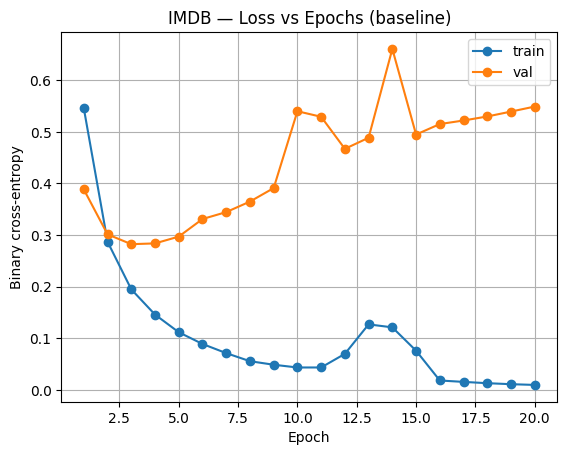

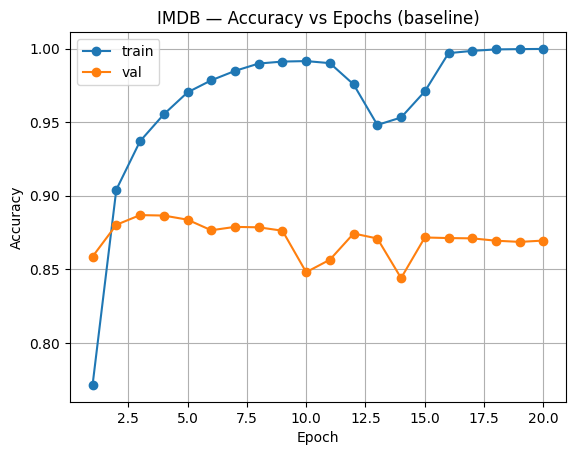

In [31]:
# 9.7–9.8 Plot training/validation loss & accuracy vs epochs

hist = history.history
epochs = range(1, len(hist["loss"]) + 1)

# Loss
plt.figure()
plt.plot(epochs, hist["loss"], marker="o", label="train")
plt.plot(epochs, hist["val_loss"], marker="o", label="val")
plt.title("IMDB — Loss vs Epochs (baseline)")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.legend()
plt.grid(True)
plt.show()

# Accuracy
plt.figure()
plt.plot(epochs, hist["accuracy"], marker="o", label="train")
plt.plot(epochs, hist["val_accuracy"], marker="o", label="val")
plt.title("IMDB — Accuracy vs Epochs (baseline)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


**3.9 Tune model hyperparameters (number of layers, hidden units, activation functions, loss functions) andretrain. Report evaluation on validation data.**

In [33]:
# --- 9.9 Hyperparameter sweep (robust to tuple-valued params like layers_spec) ---

from collections import OrderedDict
from itertools import product

def build_model_hp(input_dim, layers_spec=(16, 16), activation="relu", dropout=0.0, lr=1e-3, loss="binary_crossentropy"):
    m = keras.Sequential([layers.Input(shape=(input_dim,))])
    # ensure tuple so Keras gets consistent shapes
    if not isinstance(layers_spec, (list, tuple)):
        layers_spec = (int(layers_spec),)
    for h in layers_spec:
        m.add(layers.Dense(int(h), activation=activation))
        if dropout and float(dropout) > 0:
            m.add(layers.Dropout(float(dropout)))
    m.add(layers.Dense(1, activation="sigmoid"))
    m.compile(
        optimizer=keras.optimizers.Adam(learning_rate=float(lr)),
        loss=loss,
        metrics=["accuracy"]
    )
    return m

hp_grid = OrderedDict({
    "layers_spec": [(16,), (32,), (16,16), (32,16), (32,32)],
    "activation":  ["relu", "tanh"],
    "dropout":     [0.0, 0.2],
    "lr":          [1e-3, 3e-4],
    "loss":        ["binary_crossentropy"],
})

def cartesian_product(grid: OrderedDict):
    keys = list(grid.keys())
    # IMPORTANT: do NOT use np.meshgrid here; tuples in layers_spec break it.
    for values in product(*(grid[k] for k in keys)):
        yield {k: v for k, v in zip(keys, values)}

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

results = []
for params in cartesian_product(hp_grid):
    model = build_model_hp(NUM_WORDS, **params)
    h = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=30,
        batch_size=512,
        callbacks=[early_stop],
        verbose=0
    )
    val_acc  = float(max(h.history["val_accuracy"]))
    val_loss = float(min(h.history["val_loss"]))
    results.append({
        **params,
        "best_val_acc": val_acc,
        "best_val_loss": val_loss,
        "epochs_run": len(h.history["loss"])
    })

hp_df = pd.DataFrame(results).sort_values(
    ["best_val_acc", "best_val_loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(hp_df.head(10))


,layers_spec,activation,dropout,lr,loss,best_val_acc,best_val_loss,epochs_run
0,"(32,)",relu,0.2,0.0010,binary_crossentropy,0.8914,0.278054,6
1,"(32, 16)",tanh,0.2,0.0003,binary_crossentropy,0.8909,0.272851,11
2,"(16,)",relu,0.0,0.0010,binary_crossentropy,0.8909,0.278555,8
3,"(32, 16)",relu,0.2,0.0003,binary_crossentropy,0.8906,0.274261,13
4,"(16,)",relu,0.2,0.0010,binary_crossentropy,0.8903,0.275329,10
5,"(16, 16)",relu,0.2,0.0003,binary_crossentropy,0.8903,0.275527,16
6,"(32, 16)",relu,0.0,0.0003,binary_crossentropy,0.8901,0.277691,11
7,"(32, 32)",relu,0.2,0.0003,binary_crossentropy,0.8900,0.275492,10
8,"(16, 16)",tanh,0.2,0.0003,binary_crossentropy,0.8899,0.273372,14
9,"(32, 32)",relu,0.0,0.0003,binary_crossentropy,0.8899,0.278621,9


## 4. Convolutional Neural Networks (CNNs)

**4.1 Use Keras to build a convolutional neural network for image classification.**

**4.2 Choose an image dataset (e.g., MNIST digits, CIFAR-10).**

**4.3 Preprocess the dataset: normalize pixel values, split into training/validation/test sets, and apply categorical encoding for labels.**

**4.4 Design a CNN with the following elements: Convolutional layers, Pooling layers, Dense classification layers.**

**4.5 Compile and train the CNN**

**4.6 Plot training and validation loss and accuracy as a function of epochs.**

**4.7 Perform a hyperparameter study: Vary number of convolutional filters. Try different kernel sizes and activation functions. Experiment with dropout for regularization**

**4.8 Evaluate final test performance and compare it to a baseline (e.g., simple fully connected network).**